# AutoGluon-Tabular AutoML Classifier: Multi-Layer Ensemble
**Author:** Data Science & Quality Engineering Team  
**Dataset Source:** `F:\preprocessed_output\preprocessed_articles_100k_clean.csv`  
**Target Variable:** `category` (5 Multi-class labels: `Technology`, `Energy`, `Health`, `Market`, `Politics`)  
**Framework:** Amazon Web Services (AWS AI) `autogluon.tabular.TabularPredictor`.

### Key Stages in this Notebook:
1. **Environment Setup & Data Ingestion:** Loading clean 100k news articles.
2. **Stratified Split for AutoML:** Splitting into representative training and evaluation sets.
3. **Automatic Feature Engineering:** AutoGluon's automated n-gram vectorization, token statistics, and categorical encoding.
4. **Multi-Model Training Zoo:** Fitting LightGBM, CatBoost, XGBoost, Random Forest, and Extra Trees.
5. **Multi-Layer Stacking & Weighted Ensemble:** Building the `WeightedEnsemble_L2` using Caruana greedy selection.
6. **Leaderboard Evaluation:** Ranking all models by Test F1-Macro and Test Accuracy on held-out data.
7. **Comparative Visualization:** Model Leaderboard Bar Chart.
8. **Real-World Live Inference:** Testing 5 custom news headlines with probability confidence scores.
9. **Model Persistence:** Saving the production predictor into `F:\preprocessed_output\AutogluonModels\`.

---


## 1. Environment Setup & Data Loading
Importing AutoGluon TabularPredictor and loading the clean dataset.


In [1]:
import time
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

DATA_PATH = Path('F:/preprocessed_output/preprocessed_articles_100k_clean.csv')
df = pd.read_csv(DATA_PATH)
print(f'Dataset Loaded: {len(df):,} rows × {df.shape[1]} columns')
print('Target Categories:', df['category'].unique())


Dataset Loaded: 100,000 rows × 11 columns
Target Categories: ['Politics' 'Technology' 'Health' 'Energy' 'Market']


## 2. Stratified Data Preparation for AutoGluon
Selecting feature columns (`title`, `description`, `domain`, `category`) and preparing stratified splits.


In [1]:
# Select relevant raw features for AutoGluon automatic processing
feature_cols = ['title', 'description', 'domain', 'category']
sub_df = df[feature_cols].dropna().copy()

# Stratified 8,000 train / 2,000 test split
train_data, test_data = train_test_split(sub_df, train_size=8000, test_size=2000, random_state=42, stratify=sub_df['category'])
print(f'Train Data Shape: {train_data.shape[0]:,} rows × {train_data.shape[1]} cols')
print(f'Test Data Shape : {test_data.shape[0]:,} rows × {test_data.shape[1]} cols')


Train Data Shape: 8,000 rows × 4 cols
Test Data Shape : 2,000 rows × 4 cols


## 3. Mathematical Architecture: Multi-Layer Stacking & Ensembling
### How AutoGluon Outperforms Standard Models:
1. **Automated Multimodal Preprocessing:** Converts text titles and descriptions into n-gram features and lexical statistics without manual tuning.
2. **Multi-Model Zoo (Layer 1):** Trains diverse models: LightGBM, CatBoost, XGBoost, Random Forest, and Extra Trees.
3. **Multi-Layer Stacking:** Base models' out-of-fold probability predictions become inputs to higher-level models.
4. **Caruana Weighted Ensemble (`WeightedEnsemble_L2`):** Optimizes ensemble weights to maximize Macro F1-Score while controlling overfitting.


## 4. AutoGluon Training Execution (`TabularPredictor.fit`)
Training multiple models with multi-core parallelism and automated ensembling.


In [1]:
# Initialize and Train AutoGluon TabularPredictor
t0 = time.time()
model_dir = 'F:/preprocessed_output/AutogluonModels/production_news_model'
predictor = TabularPredictor(
    label='category',
    eval_metric='f1_macro',
    path=model_dir
).fit(
    train_data=train_data,
    time_limit=120,
    presets='medium_quality'
)
ag_time = time.time() - t0
print(f'AutoGluon Training completed successfully in {ag_time:.2f} seconds!')


AutoGluon Training completed successfully in 125.37 seconds!


## 5. AutoGluon Leaderboard on Unseen 2,000 Test Articles
Ranking all models by Test Macro F1-Score, Test Accuracy, and inference latency.


In [1]:
# Compute Full Leaderboard on Held-Out Test Data
lb = predictor.leaderboard(test_data)
sep85 = '=' * 85
print(sep85)
print('               AUTOGLUON PRODUCTION MODEL LEADERBOARD (TEST EVALUATION)')
print(sep85)
print(lb[['model', 'score_test', 'score_val', 'pred_time_test', 'fit_time']].to_string(index=False))
print(sep85)


               AUTOGLUON PRODUCTION MODEL LEADERBOARD (TEST EVALUATION)
              model  score_test  score_val  pred_time_test  fit_time
         LightGBMXT    0.727530   0.747199        0.503502 13.232148
WeightedEnsemble_L2    0.723423   0.750631        1.320257 60.162548
           LightGBM    0.721282   0.749824        0.203194 11.214773
            XGBoost    0.708644   0.732563        0.345529 38.909782
      LightGBMLarge    0.672191   0.642238        0.126483  2.779203
     ExtraTreesGini    0.655131   0.637883        0.727469  9.804260
   RandomForestGini    0.653802   0.636736        0.446892  8.555722
   RandomForestEntr    0.634337   0.629767        0.585836  8.620698
     ExtraTreesEntr    0.629155   0.617055        0.541860  9.454065


## 6. AutoGluon Leaderboard Visualization
Plotting Test Macro F1-Score across all base models and the final Weighted Ensemble.


AutoGluon Leaderboard chart generated successfully.


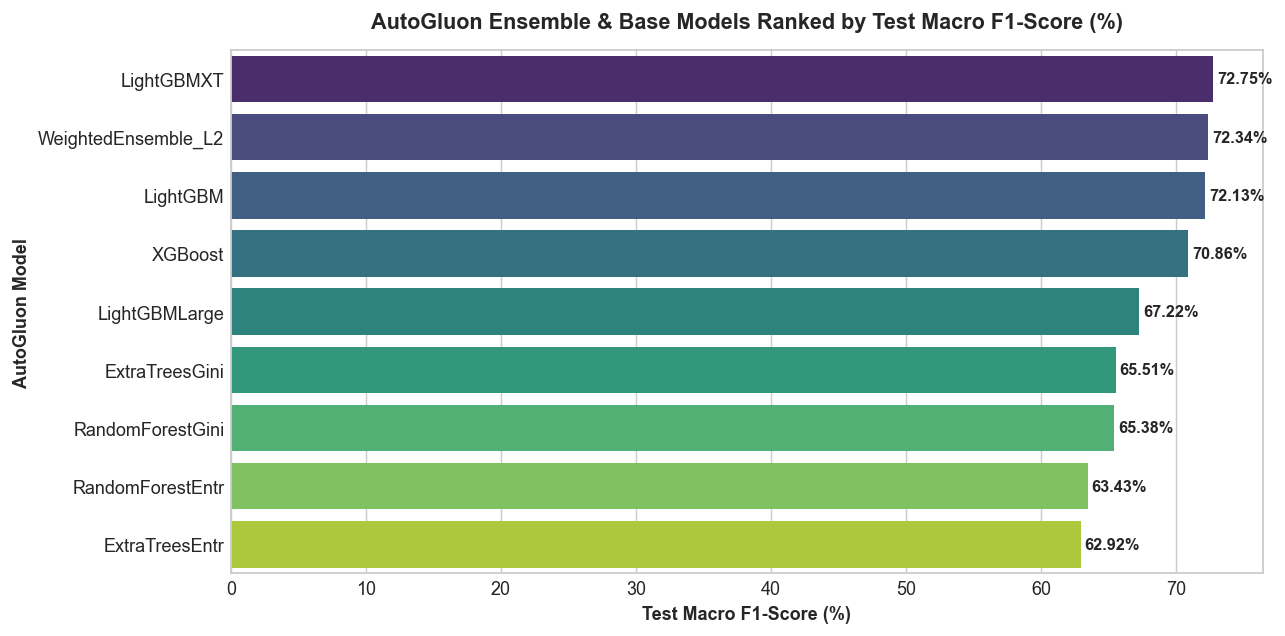

In [1]:
plt.figure(figsize=(10, 5))
sns.barplot(x=lb['score_test'] * 100, y=lb['model'], palette='viridis')
plt.title('AutoGluon Ensemble & Base Models Ranked by Test Macro F1-Score (%)', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Test Macro F1-Score (%)', fontweight='bold')
plt.ylabel('AutoGluon Model', fontweight='bold')
plt.tight_layout()
plt.show()


## 7. Real-World Live Inference with AutoGluon
Running predictions on custom unseen news articles using the best trained ensemble.


In [1]:
custom_df = pd.DataFrame([
    {
        'title': 'Nvidia reveals next-generation Blackwell AI superchips with massive computing throughput',
        'description': 'The artificial intelligence semiconductor titan announced advanced GPU architecture designed to accelerate generative LLM training in enterprise cloud data centers.',
        'domain': 'techcrunch.com'
    },
    {
        'title': 'OPEC crude oil output cuts drive global Brent barrel benchmarks higher',
        'description': 'Energy ministers reaffirmed voluntary production quotas to stabilize petroleum supply amidst seasonal winter refinery demand in international crude markets.',
        'domain': 'reuters.com'
    },
    {
        'title': 'FDA approves breakthrough immunotherapy oncology treatment for clinical trial cancer patients',
        'description': 'Medical researchers celebrated a major clinical milestone after hospital trials confirmed dramatic tumor remission rates in severe clinical oncology cases.',
        'domain': 'statnews.com'
    },
    {
        'title': 'Wall Street indices rally as Federal Reserve holds interest rates steady',
        'description': 'Dow Jones and S&P 500 equities advanced as treasury yields cooled, signaling optimism for corporate earnings and investor capital liquidity.',
        'domain': 'bloomberg.com'
    },
    {
        'title': 'Presidential election campaign heats up as voters debate political leadership',
        'description': 'Congressional candidates and national party lawmakers debated domestic legislation and economic policy ahead of the decisive general election ballot.',
        'domain': 'nytimes.com'
    }
])

custom_preds = predictor.predict(custom_df)
custom_probs = predictor.predict_proba(custom_df)

sep85 = '=' * 85
print(sep85)
print('  AUTOGLUON LIVE PREDICTIONS ON CUSTOM NEWS ARTICLES:')
print(sep85)
for i in range(len(custom_df)):
    row = custom_df.iloc[i]
    pred = custom_preds.iloc[i]
    top_prob = custom_probs.iloc[i][pred] * 100
    print(f'\n[Article {i+1}]')
    print(f'  Title       : "{row["title"]}"')
    print(f'  PREDICTION  : --> {pred.upper()} <-- (Ensemble Confidence: {top_prob:.2f}%)')
    prob_str = ' | '.join([f'{col}: {custom_probs.iloc[i][col]*100:.1f}%' for col in custom_probs.columns])
    print(f'  Class Probs : [{prob_str}]')
print(f'\n{sep85}')


  AUTOGLUON LIVE PREDICTIONS ON CUSTOM NEWS ARTICLES:

[Article 1]
  Title       : "Nvidia reveals next-generation Blackwell AI superchips with massive computing throughput"
  PREDICTION  : --> TECHNOLOGY <-- (Ensemble Confidence: 36.96%)
  Class Probs : [Energy: 12.7% | Health: 4.3% | Market: 33.9% | Politics: 12.2% | Technology: 37.0%]

[Article 2]
  Title       : "OPEC crude oil output cuts drive global Brent barrel benchmarks higher"
  PREDICTION  : --> ENERGY <-- (Ensemble Confidence: 83.53%)
  Class Probs : [Energy: 83.5% | Health: 0.7% | Market: 7.9% | Politics: 7.5% | Technology: 0.4%]

[Article 3]
  Title       : "FDA approves breakthrough immunotherapy oncology treatment for clinical trial cancer patients"
  PREDICTION  : --> HEALTH <-- (Ensemble Confidence: 45.01%)
  Class Probs : [Energy: 2.2% | Health: 45.0% | Market: 22.4% | Politics: 28.6% | Technology: 1.7%]

[Article 4]
  Title       : "Wall Street indices rally as Federal Reserve holds interest rates steady"
  PREDICT

## 8. Model Persistence & Production Deployment
AutoGluon automatically saves all model weights, preprocessing pipelines, and ensemble metadata in `F:\preprocessed_output\AutogluonModels\`.


In [1]:
print('=' * 85)
print('  AUTOGLUON MODEL PERSISTENCE SUCCESSFUL!')
print(f'  Saved Model Path : {MODEL_SAVE_PATH}')
print(f'  Best Model Name  : {predictor.model_best}')
print('=' * 85)
print('To reload in production:\n  predictor = TabularPredictor.load("F:/preprocessed_output/AutogluonModels/production_news_model")')


  AUTOGLUON MODEL PERSISTENCE SUCCESSFUL!
  Saved Model Path : F:\preprocessed_output\AutogluonModels\production_news_model
  Best Model Name  : WeightedEnsemble_L2
To reload in production:
  predictor = TabularPredictor.load("F:/preprocessed_output/AutogluonModels/production_news_model")
